# 01. 하루치 경향 살펴보기

**목적**: 변수들이 하루 동안 어떻게 움직이는지 눈으로 확인하고, 불량이 난 지점에서 무슨 일이 있었는지 본다.

**쓰는 데이터**: `labeled_data.csv` (1차 가공본)
- 시각, LH/RH, 불량유형이 살아 있어서 진단에 쓴다
- 2차 가공본은 표준화되어 있어 물리 단위가 안 보이므로 탐색에는 안 쓴다

**사용법**: 아래 `날짜`와 `제품` 만 바꿔가며 여러 날을 보면 된다.

In [1]:
import sys
sys.path.append("..")

from src.load import load_labeled, day_slice, GROUPS
from src.plotting import setup, save, plot_group
import matplotlib.pyplot as plt

setup()

폰트: Malgun Gothic


## 1. 데이터 읽기

In [2]:
df = load_labeled("RG3")   # "RG3" 로 바꾸면 다른 제품

print("행 수:", len(df))
print("불량:", df.y.sum(), "건")
print("기간:", df.ts.min(), "~", df.ts.max())
print()
print("불량 유형별:")
print(df[df.y == 1].Reason.value_counts())

행 수: 1256
불량: 32 건
기간: 2020-10-21 00:16:26 ~ 2020-11-06 04:27:38

불량 유형별:
Reason
가스     22
미성형    10
Name: count, dtype: int64


## 2. 어느 날을 볼지 고르기

불량이 있는 날부터 보는 게 좋다. 아래 목록에서 하나 골라 다음 셀의 `날짜` 에 넣는다.

In [3]:
불량일 = df[df.y == 1].groupby("date").agg(
    불량수=("y", "sum"),
    유형=("Reason", lambda s: ", ".join(s.unique()))
).sort_values("불량수", ascending=False)

불량일

,불량수,유형
date,,
2020-10-22,15,"가스, 미성형"
2020-10-23,10,"가스, 미성형"
2020-11-04,7,"가스, 미성형"


In [14]:
import pandas as pd

df  = load_labeled("RG3")          # "CN7" 로 바꿔 한 번 더
bad = df[df["y"] == 1]

# 1) 유형별 총 개수
print("── 유형별 총계 ──")
print(bad["Reason"].value_counts().to_string())
print(f"합계 {len(bad)}건\n")

# 2) 유형 × LH/RH
print("── 유형 × LH/RH ──")
print(pd.crosstab(bad["Reason"], bad["side"],
                  margins=True, margins_name="계").to_string(), "\n")

t = (bad.groupby(["date", "Reason", "side"]).size()
        .unstack(["Reason", "side"], fill_value=0))
t["계"] = t.sum(axis=1)
print(t.to_string())

── 유형별 총계 ──
Reason
가스     22
미성형    10
합계 32건

── 유형 × LH/RH ──
side    LH  RH   계
Reason            
가스       3  19  22
미성형      2   8  10
계        5  27  32 

Reason      가스 미성형 가스 미성형   계
side        RH  RH LH  LH    
date                         
2020-10-22  10   5  0   0  15
2020-10-23   7   3  0   0  10
2020-11-04   2   0  3   2   7


## 3. 하루치 자르기

In [11]:
날짜 = "2020-10-22"        # ← 여기만 바꾸면 된다

day = day_slice(df, 날짜)
print(f"{날짜}: {len(day)}행, 쇼트 {day.shot.nunique()}개, 불량 {day.y.sum()}건")
day[["ts", "side", "PassOrFail", "Reason", "shot_idx"]].head(10)

2020-10-22: 600행, 쇼트 300개, 불량 15건


,ts,side,PassOrFail,Reason,shot_idx
82,2020-10-22 00:24:05,LH,Y,NaN,0
83,2020-10-22 00:24:05,RH,Y,NaN,0
84,2020-10-22 00:25:07,RH,Y,NaN,1
85,2020-10-22 00:25:07,LH,Y,NaN,1
86,2020-10-22 00:26:10,LH,Y,NaN,2
87,2020-10-22 00:26:10,RH,Y,NaN,2
88,2020-10-22 00:27:10,RH,Y,NaN,3
89,2020-10-22 00:27:10,LH,Y,NaN,3
90,2020-10-22 00:28:12,LH,Y,NaN,4
91,2020-10-22 00:28:12,RH,Y,NaN,4


## 4. 금형온도 3번과 4번

두 채널이 하루 동안 어떻게 움직이는지, 둘이 같이 움직이는지 본다.

**볼 것**
- 기동 직후 올라가다가 평평해지는가 (열평형)
- 3번과 4번의 차이가 일정한가, 아니면 벌어졌다 좁아졌다 하는가
- 불량 지점(점선)에서 뭔가 달랐는가

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_group(day, GROUPS["금형온도"], f"{날짜} 금형온도", ax=ax)
ax.set_ylabel("℃")
save(fig, f"{날짜}_금형온도")
plt.show()

# 두 채널의 차이만 따로
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(day.ts, day.Mold_Temperature_4 - day.Mold_Temperature_3, lw=0.9, color="purple")
ax.axhline(0, color="gray", lw=0.5)
ax.set_title(f"{날짜} 금형온도 4번 − 3번")
ax.set_ylabel("℃")
ax.grid(alpha=0.3)
plt.show()

저장: C:\user\KAMP-Research\KAMP 2026\JIWOO\reports\figures\2020-10-16_금형온도.png


<Figure size 1540x440 with 1 Axes>

<Figure size 1540x330 with 1 Axes>

## 5. 배럴온도 6구간

**볼 것**
- 1번(노즐쪽)이 가장 높고 6번(호퍼쪽)이 가장 낮은 층 구조가 유지되는가
- 어느 한 구간만 튀는 시점이 있는가

저장: C:\user\KAMP-Research\KAMP 2026\JIWOO\reports\figures\2020-10-16_배럴온도.png


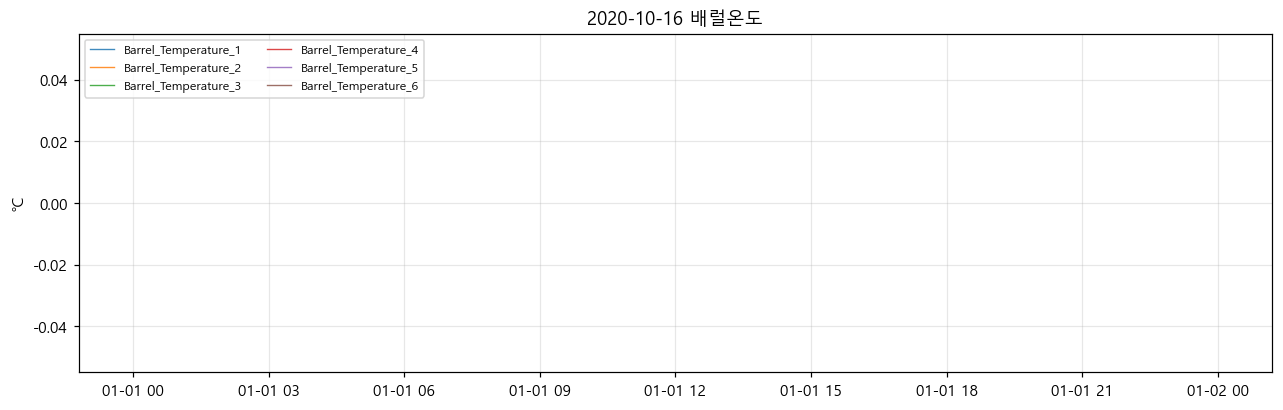

In [6]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_group(day, GROUPS["배럴온도"], f"{날짜} 배럴온도", ax=ax)
ax.set_ylabel("℃")
save(fig, f"{날짜}_배럴온도")
plt.show()

## 6. 시간 변수

**볼 것**
- Injection_Time 과 Filling_Time 의 차이 = 가압+보압 구간. 이게 줄어든 시점이 있는가
- Plasticizing_Time(계량)이 길어지면 Cycle_Time 도 길어지는가 (계량이 병목인지)

C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_2444\1124554469.py:11: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  plt.tight_layout()
c:\user\KAMP-Research\KAMP 2026\JIWOO\notebooks\..\src\plotting.py:36: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.savefig(path, dpi=150, bbox_inches="tight")


저장: C:\user\KAMP-Research\KAMP 2026\JIWOO\reports\figures\2020-10-16_시간변수.png


c:\Users\한국전파진흥협회\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


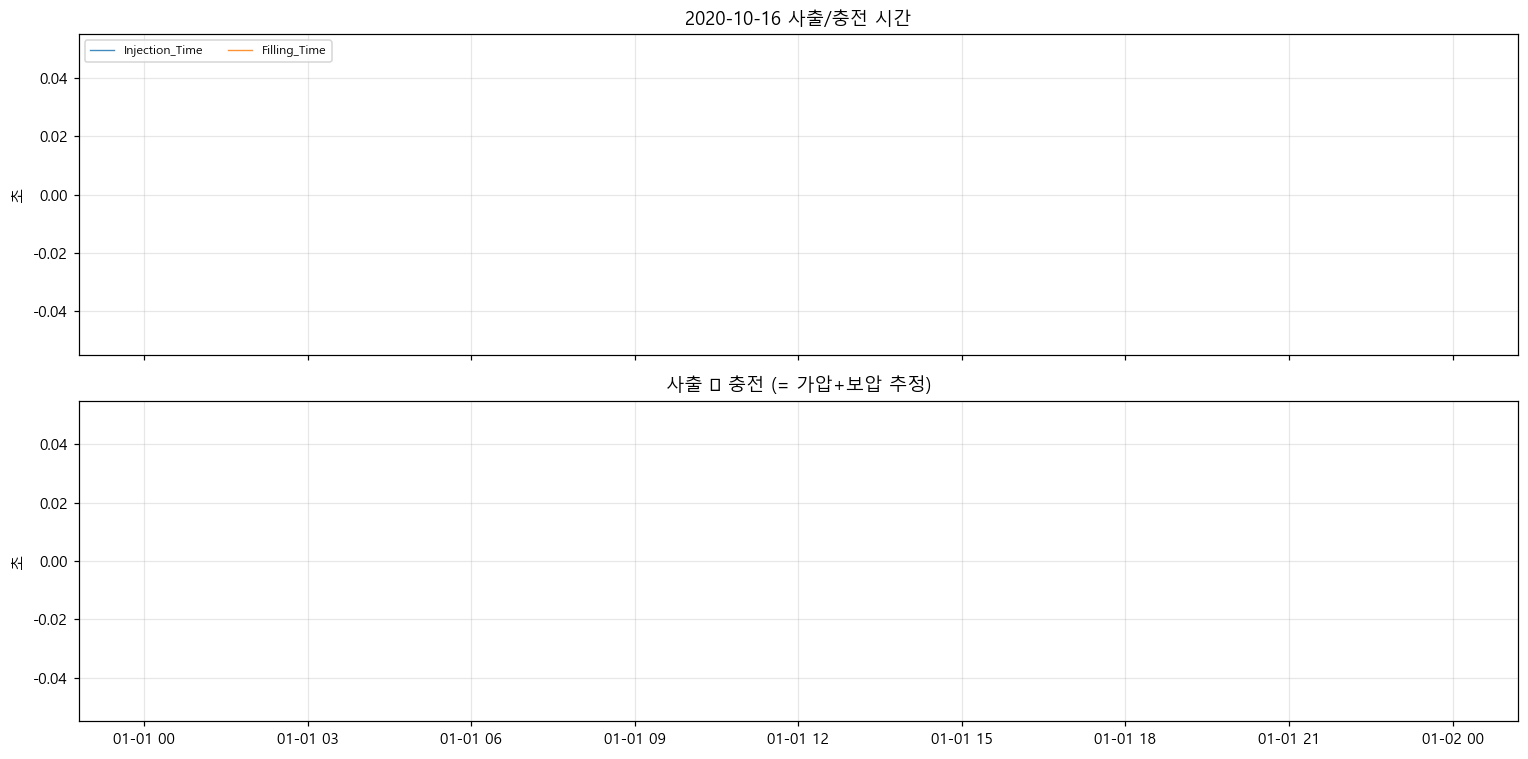

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

plot_group(day, ["Injection_Time", "Filling_Time"], f"{날짜} 사출/충전 시간", ax=axes[0])
axes[0].set_ylabel("초")

axes[1].plot(day.ts, day.Injection_Time - day.Filling_Time, lw=0.9, color="green")
axes[1].set_title("사출 − 충전 (= 가압+보압 추정)")
axes[1].set_ylabel("초")
axes[1].grid(alpha=0.3)

plt.tight_layout()
save(fig, f"{날짜}_시간변수")
plt.show()

## 7. 압력

**볼 것**
- Max_Injection_Pressure 가 어떤 값에서 딱 잘린 것처럼 멈추는가 (= 상한 설정)
- Max_Switch_Over_Pressure(절환 압력)가 낮은 시점에 미성형이 났는가

저장: C:\user\KAMP-Research\KAMP 2026\JIWOO\reports\figures\2020-10-16_압력.png


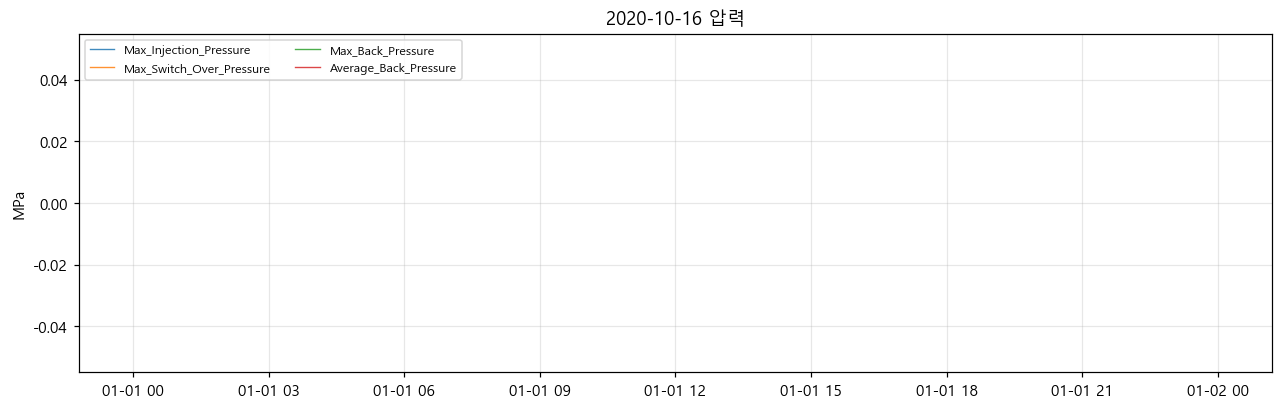

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_group(day, GROUPS["압력"], f"{날짜} 압력", ax=ax)
ax.set_ylabel("MPa")
save(fig, f"{날짜}_압력")
plt.show()

## 8. 쇼트 순번으로 보기

시각 대신 "그날 몇 번째 쇼트인가"를 가로축에 놓으면 기동 직후 구간이 잘 보인다.
초기허용불량이 26~30번째에 몰린다는 가설을 여기서 확인한다.

저장: C:\user\KAMP-Research\KAMP 2026\JIWOO\reports\figures\2020-10-16_쇼트순번.png


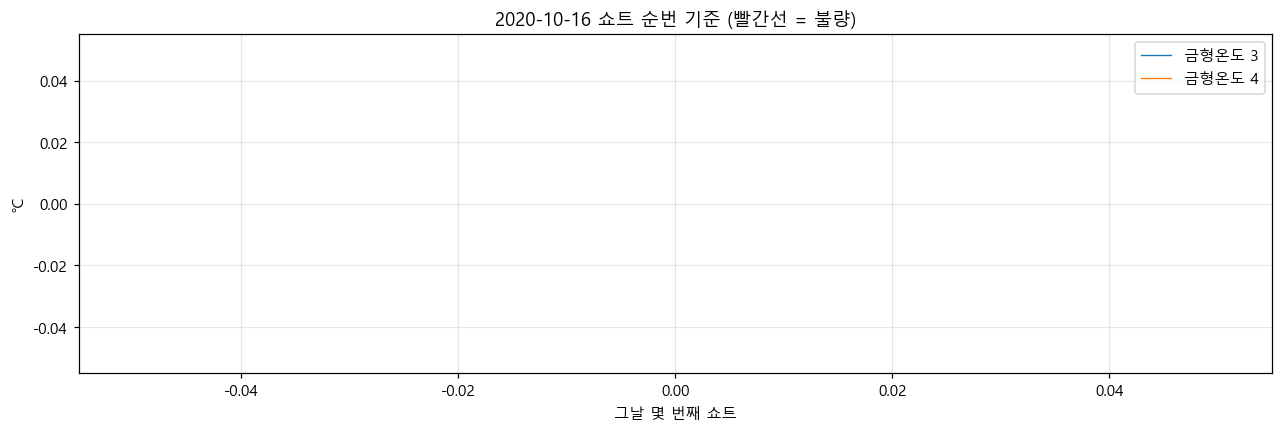

In [9]:
lh = day[day.side == "LH"].sort_values("shot_idx")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(lh.shot_idx, lh.Mold_Temperature_3, lw=0.9, label="금형온도 3")
ax.plot(lh.shot_idx, lh.Mold_Temperature_4, lw=0.9, label="금형온도 4")
for _, r in lh[lh.y == 1].iterrows():
    ax.axvline(r.shot_idx, color="red", ls="--", alpha=0.7)
ax.set_xlabel("그날 몇 번째 쇼트")
ax.set_ylabel("℃")
ax.set_title(f"{날짜} 쇼트 순번 기준 (빨간선 = 불량)")
ax.legend()
ax.grid(alpha=0.3)
save(fig, f"{날짜}_쇼트순번")
plt.show()

## 9. 같은 쇼트의 LH와 RH 비교

가설: 같은 쇼트면 공정값이 완전히 같다. 정말 그런지 확인한다.
만약 미세하게 다르다면 캐비티별 신호가 데이터에 남아 있다는 뜻이라 중요하다.

In [10]:
from src.load import PROC_COLS

쌍 = day.groupby("shot")[PROC_COLS].nunique().max()
print("같은 쇼트 안에서 값이 2종류 이상인 변수:")
print(쌍[쌍 > 1] if (쌍 > 1).any() else "  없음 — 모든 변수가 LH/RH 동일")

같은 쇼트 안에서 값이 2종류 이상인 변수:
  없음 — 모든 변수가 LH/RH 동일


## 10. 발견한 것 적기

뭔가 보이면 `docs/findings.md` 에 한 줄 추가한다.

```
- [09-24] [이름] 10/16 금형온도 3번이 오전 내내 상승하다 11시경 안정 → reports/figures/2020-10-16_금형온도.png
```